In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("employee_data.csv")

In [3]:
df.head()

,EmployeeID,Name,Gender,Age,Department,City,Experience,Salary,MonthlySales
0,E1001,Hira Shah,Female,30,Operations,Islamabad,7,79300,47500
1,E1002,Ali Siddiqui,Male,30,Sales,Hyderabad,3,68900,93500
2,E1003,Hassan Siddiqui,Male,25,Marketing,Karachi,1,63700,54800
3,E1004,Usman Farooqui,Male,31,Finance,Lahore,9,127000,183700
4,E1005,Zainab Farooqui,Female,34,IT,Islamabad,9,147100,74000


In [7]:
print("First 5 Rows:")
print(df.head())

First 5 Rows:
  EmployeeID             Name  Gender  Age  Department       City  Experience  \
0      E1001        Hira Shah  Female   30  Operations  Islamabad           7   
1      E1002     Ali Siddiqui    Male   30       Sales  Hyderabad           3   
2      E1003  Hassan Siddiqui    Male   25   Marketing    Karachi           1   
3      E1004   Usman Farooqui    Male   31     Finance     Lahore           9   
4      E1005  Zainab Farooqui  Female   34          IT  Islamabad           9   

   Salary  MonthlySales  
0   79300         47500  
1   68900         93500  
2   63700         54800  
3  127000        183700  
4  147100         74000  


In [5]:
print("\nData Types:")
print(df.dtypes)


Data Types:
EmployeeID      object
Name            object
Gender          object
Age              int64
Department      object
City            object
Experience       int64
Salary           int64
MonthlySales     int64
dtype: object


In [6]:
print("\nSummary Statistics:")
print(df.describe())


Summary Statistics:
              Age  Experience       Salary   MonthlySales
count  200.000000  200.000000     200.0000     200.000000
mean    31.740000    6.850000  101146.5000  102877.000000
std      4.876608    4.508785   32055.0216   47188.006003
min     23.000000    1.000000   52200.0000   24900.000000
25%     28.000000    3.000000   76800.0000   65500.000000
50%     31.000000    6.000000   94450.0000   92800.000000
75%     34.250000    9.000000  116450.0000  126425.000000
max     47.000000   24.000000  237500.0000  249600.000000


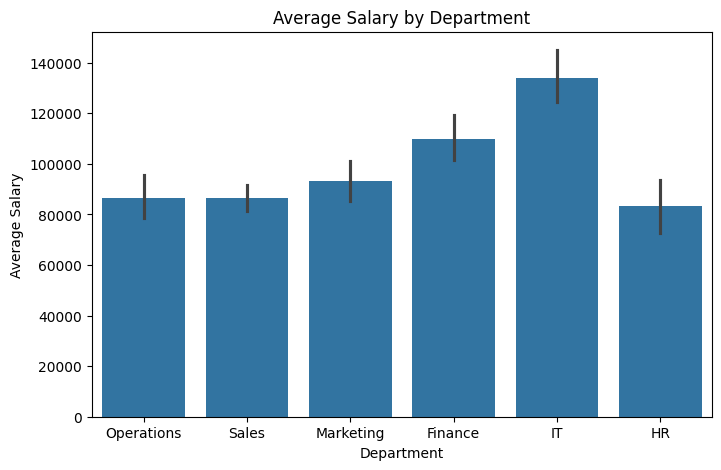

Average Salary by Department:
Department
Finance       109940.000000
HR             83250.000000
IT            134136.363636
Marketing      93420.689655
Operations     86428.000000
Sales          86691.666667
Name: Salary, dtype: float64

Department with Highest Average Salary:
IT


In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(x='Department', y='Salary', data=df)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")

plt.show()

avg_salary = df.groupby('Department')['Salary'].mean()

print("Average Salary by Department:")
print(avg_salary)

print("\nDepartment with Highest Average Salary:")
print(avg_salary.idxmax())

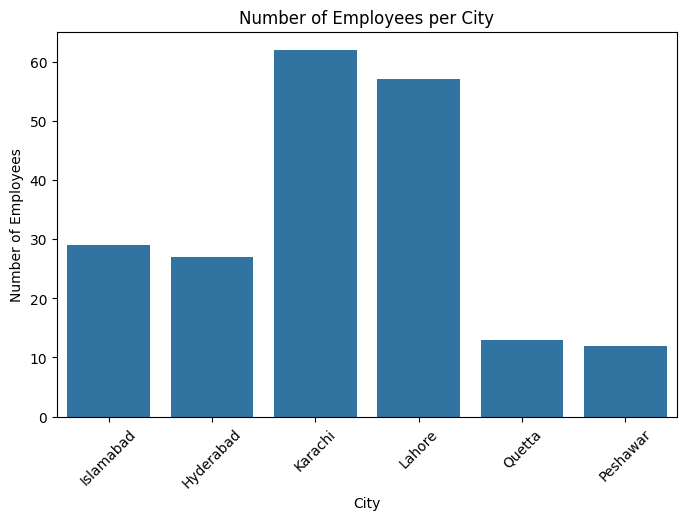

Employees per City:
City
Karachi      62
Lahore       57
Islamabad    29
Hyderabad    27
Quetta       13
Peshawar     12
Name: count, dtype: int64

City with Most Employees:
Karachi


In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(x='City', data=df)

plt.title("Number of Employees per City")
plt.xlabel("City")
plt.ylabel("Number of Employees")

plt.xticks(rotation=45)
plt.show()

city_count = df['City'].value_counts()

print("Employees per City:")
print(city_count)

print("\nCity with Most Employees:")
print(city_count.idxmax())

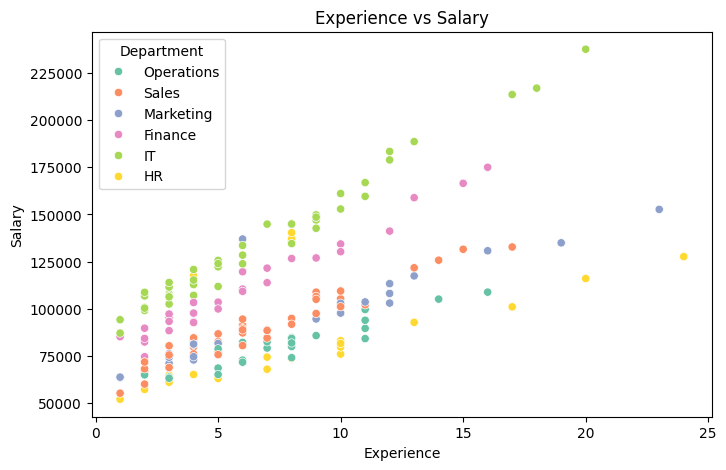

Correlation between Experience and Salary: 0.6353254710441478
Salary generally increases with experience.


In [10]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='Experience',
    y='Salary',
    data=df,
    hue='Department',
    palette='Set2'
)

plt.title("Experience vs Salary")
plt.xlabel("Experience")
plt.ylabel("Salary")

plt.show()

correlation = df['Experience'].corr(df['Salary'])

print("Correlation between Experience and Salary:", correlation)

if correlation > 0:
    print("Salary generally increases with experience.")
elif correlation < 0:
    print("Salary generally decreases with experience.")
else:
    print("There is no linear relationship between experience and salary.")

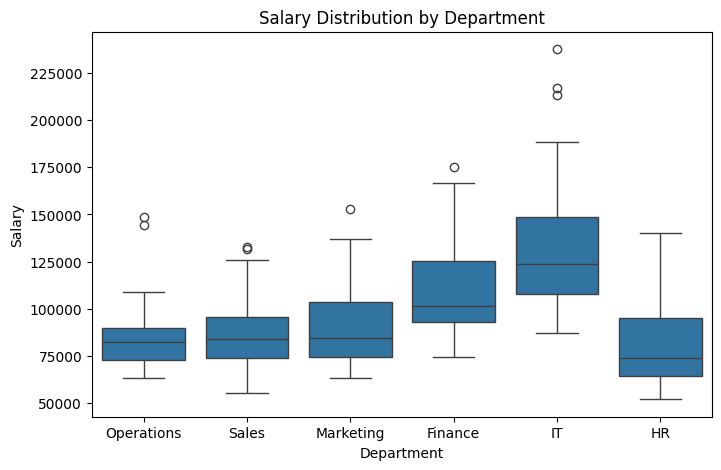

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(x='Department', y='Salary', data=df)

plt.title("Salary Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Salary")

plt.show()

In [13]:
for department in df['Department'].dropna().unique():

    salaries = df[df['Department'] == department]['Salary'].dropna()

    Q1 = salaries.quantile(0.25)
    Q3 = salaries.quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = salaries[(salaries < lower) | (salaries > upper)]

    print("\nDepartment:", department)
    print("Number of Outliers:", len(outliers))
    print("Outlier Values:", list(outliers))


Department: Operations
Number of Outliers: 2
Outlier Values: [148700, 144700]

Department: Sales
Number of Outliers: 2
Outlier Values: [132800, 131600]

Department: Marketing
Number of Outliers: 1
Outlier Values: [152700]

Department: Finance
Number of Outliers: 1
Outlier Values: [175000]

Department: IT
Number of Outliers: 3
Outlier Values: [237500, 213500, 216900]

Department: HR
Number of Outliers: 0
Outlier Values: []


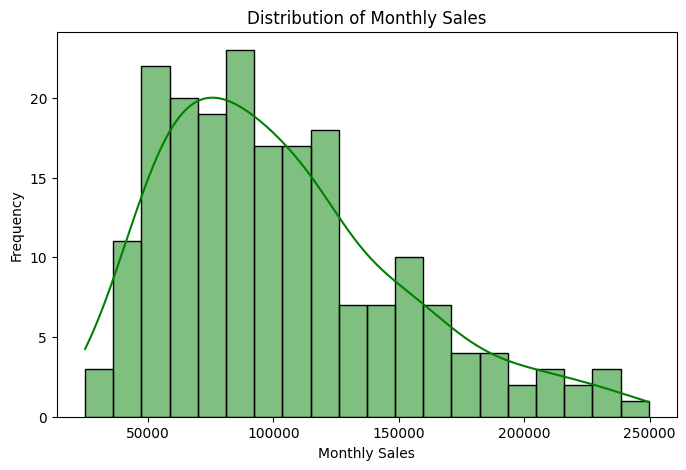

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['MonthlySales'].dropna(),
    bins=20,
    kde=True,
    color='green'
)

plt.title("Distribution of Monthly Sales")
plt.xlabel("Monthly Sales")
plt.ylabel("Frequency")

plt.show()

In [15]:
skewness = df['MonthlySales'].skew()

print("Monthly Sales Skewness:", skewness)

if skewness > 0.5:
    print("The data is positively skewed (Right Skewed).")
elif skewness < -0.5:
    print("The data is negatively skewed (Left Skewed).")
else:
    print("The data is approximately symmetrical.")

Monthly Sales Skewness: 0.8813728912546781
The data is positively skewed (Right Skewed).


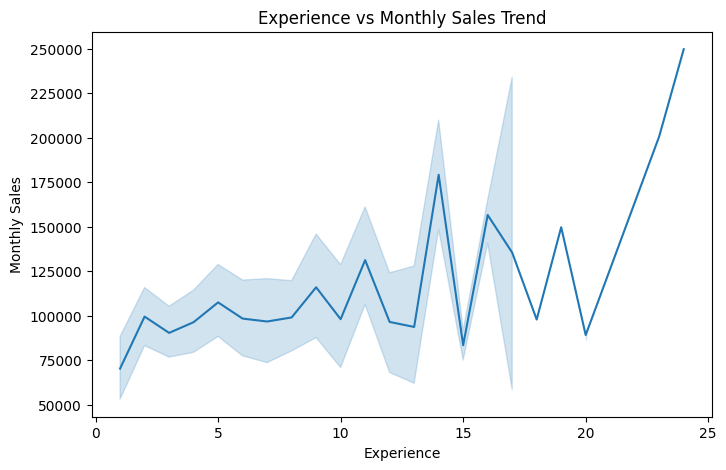

In [16]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    x='Experience',
    y='MonthlySales',
    data=df
)
plt.title("Experience vs Monthly Sales Trend")
plt.xlabel("Experience")
plt.ylabel("Monthly Sales")
plt.show()

In [17]:
sales_correlation = df['Experience'].corr(df['MonthlySales'])

print("Correlation between Experience and Monthly Sales:",
      sales_correlation)

if sales_correlation > 0:
    print("Sales performance generally increases with experience.")
elif sales_correlation < 0:
    print("Sales performance generally decreases with experience.")
else:
    print("There is no linear relationship between experience and sales.")

Correlation between Experience and Monthly Sales: 0.26381151169664285
Sales performance generally increases with experience.
